# 1. Erster Lauf: Tracer-Diffusion

**Frage.** Löst der Transportteil des Codes die Diffusion richtig, und wie rechnet man einen Fall und liest seine Ausgabe?

## Das physikalische Problem

Eine 10 mm lange Säule aus porösem Material ist vollständig wassergesättigt. Anfangs enthält das Porenwasser keinen Tracer.
Ab $t = 0$ berührt das linke Ende eine Lösung mit $c = 1$ mol/m³, das rechte eine Lösung mit $c = 0$. Der Tracer dringt nur
durch Diffusion in die Säule ein. Nichts reagiert, nichts strömt, und das Material ändert sich nicht.

## Modellannahmen

- ein nicht reaktiver Tracer, keine Chemie (GEMS wird nicht aufgerufen);
- gesättigte Poren, konstante Porosität φ = 0,4 und konstanter effektiver Diffusionskoeffizient $D_e = 4\times10^{-10}$ m²/s;
- keine Strömung, Transport nur durch Diffusion: $\phi\,\partial c/\partial t = \partial_x (D_e\,\partial_x c)$;
- beide Enden auf fester Konzentration (Dirichlet-Ränder).

Unter diesen Annahmen hat das Problem eine exakte Lösung; deshalb taugt es als Test.

## Von den Annahmen zu `case.yaml`

| Annahme | Schlüssel in `case.yaml` |
|---|---|
| keine Chemie, ein Tracer | `coupling.mode: diffusion`, `transport.components: [tracer]` |
| Porenwasser anfangs ohne Tracer | `transport.initial: {tracer: 0.0}` |
| φ und $D_e$ konstant | `transport.material`, `update_porosity: false`, `update_diffusivity: false` |
| feste Konzentration an beiden Enden | `boundary.left/right.type: dirichlet` mit `concentrations` |
| 10 mm, 50 Zellen, 20 000 s in Schritten von 100 s | `geometry`, `coupling.time` |

Die erste Codezelle findet den Ordner `FEniCSx_GEMS`, egal wo im Repository das Notebook geöffnet wird, und arbeitet in einem Ordner
`tutorial_runs/` daneben:

```text
FEniCSx_GEMS/                       die vier Module + chemistry_data/
tutorial_runs/t01_tracer/case.yaml  wird unten geschrieben
tutorial_runs/t01_tracer/results/   entsteht beim Lauf
```

## Die Eingabedatei schreiben

`case.yaml` hat immer dieselben vier Abschnitte, einen pro Python-Modul. Im Modus diffusion werden nur `transport`, `coupling` und `output` gelesen;
`chemistry` muss vorhanden sein, wird aber nicht verwendet.

Die Zeile `%%writefile` unten schreibt die Zelle in eine Datei. Außerhalb eines Notebooks bearbeiten Sie `case.yaml` einfach im Texteditor.

In [1]:
import os, sys
from pathlib import Path
# Find the FEniCSx_GEMS folder, wherever this notebook is opened inside the repository
here = Path.cwd()
code = next(p / 'FEniCSx_GEMS' for p in [here, *here.parents] if (p / 'FEniCSx_GEMS' / 'coupling.py').exists())
PY = sys.executable                         # the Python of this kernel runs coupling.py
work = code.parent / 'tutorial_runs'       # tutorial cases go here, next to FEniCSx_GEMS
work.mkdir(exist_ok=True)
os.chdir(work)
os.makedirs('t01_tracer', exist_ok=True)
print('working in', work.name, 'next to', code.name)

working in tutorial_runs next to FEniCSx_GEMS


In [2]:
%%writefile t01_tracer/case.yaml
# Tutorial 1: one tracer diffusing through a porous column, no chemistry.

chemistry:                       # not used in diffusion mode, but the section must exist
  project: ../../FEniCSx_GEMS/chemistry_data/b_time0-dat.lst
  temperature: 298.15
  pressure: 100000
  aqueous_phase: aq_gen
  solid_phases: []
  gibbs: {}
  initial: {}

transport:
  geometry:
    length: 0.01                 # m
    cells: 50                    # uniform 1D mesh, dx = 0.2 mm
  material:
    phi: 0.4                     # porosity
    De: 4.0e-10                  # effective diffusion coefficient, m2/s
  components: [tracer]           # names of the transported tracers
  initial: {tracer: 0.0}         # mol/m3 pore water
  boundary:
    left:
      type: dirichlet
      concentrations: {tracer: 1.0}
    right:
      type: dirichlet
      concentrations: {tracer: 0.0}
  solver:
    ksp_type: preonly
    pc_type: lu
    rtol: 1.0e-10
    max_iterations: 1000

coupling:
  mode: diffusion                # diffusion | chemistry | coupled
  time:
    dt: 100                      # s
    end: 20000                   # s
  update_porosity: false         # must be false without chemistry
  update_diffusivity: false
  exponent: 1.0                  # unused here

output:
  folder: results                # relative to this case.yaml
  every: 50                      # write profiles every 50 steps (5000 s)

Overwriting t01_tracer/case.yaml


## Rechnen

Im Terminal in `tutorial_runs/` lautet der Befehl `python ../FEniCSx_GEMS/coupling.py t01_tracer/case.yaml`.
Die Zeile `!{PY}` führt denselben Befehl im Notebook aus, mit dem Python des Notebooks.

In [3]:
!{PY} ../FEniCSx_GEMS/coupling.py t01_tracer/case.yaml

step=0, time=0 s, balance=0.000e+00 mol/m2, chemistry=0.000e+00 mol/m3, water mismatch=0.00%
step=50, time=5000 s, balance=6.505e-18 mol/m2, chemistry=0.000e+00 mol/m3, water mismatch=0.00%
step=100, time=10000 s, balance=1.691e-17 mol/m2, chemistry=0.000e+00 mol/m3, water mismatch=0.00%


step=150, time=15000 s, balance=2.992e-17 mol/m2, chemistry=0.000e+00 mol/m3, water mismatch=0.00%
step=200, time=20000 s, balance=4.380e-17 mol/m2, chemistry=0.000e+00 mol/m3, water mismatch=0.00%


Saved: tutorial_runs/t01_tracer/results


## Was der Lauf geschrieben hat

Alles landet in `output.folder`. `summary.txt` sagt, ob der Lauf COMPLETED oder FAILED ist, und nennt die größten Erhaltungsfehler.

In [4]:
print(sorted(os.listdir('t01_tracer/results')))
print(open('t01_tracer/results/summary.txt').read())

['case_used.json', 'fields.h5', 'fields.xdmf', 'mass_balance.csv', 'profiles.csv', 'profiles.png', 'simulation.log', 'summary.txt']
COMPLETED
Mode: diffusion
Cells/states: 50; reference length: 0.01 m
Scheme: backward Euler, DG0 two-point cell flux (transport modes only)
Linear solver: preonly / lu
Final time: 20000.0 s; steps: 200
Amounts: mol/m3 bulk; concentrations: mol/m3 pore water
Inventory and boundary exchange: mol/m2 (unit cross-sectional area)
Maximum balance error: 4.380177e-17 mol/m2
Maximum chemical element reconstruction error: 0.000000e+00 mol/m3
Maximum aqueous-volume/porosity mismatch: 0.000000%
GEMS initialisation: not used (diffusion mode)
GEMS failures: on_failure = stop; cell-steps skipped (left unreacted): 0
Final porosity range: 0.4 to 0.4
Final De range: 4e-10 to 4e-10 m2/s
Porosity feedback: False
Diffusivity feedback: False
Limit: numerical demonstration, not experimental validation.
Limit: saturated pore volume is assumed; aqueous volume mismatch is diagnosti

## Vergleich mit der analytischen Lösung

Bei konstantem $\phi$ und $D_e$ ist die Gleichung gewöhnliche Diffusion mit dem Porendiffusionskoeffizienten $D = D_e/\phi = 10^{-9}$ m²/s.
Für $c(0,t)=1$, $c(L,t)=0$ und $c(x,0)=0$:

$$
c(x,t) = 1-\frac{x}{L}-\frac{2}{\pi}\sum_{n=1}^{\infty}\frac{1}{n}\sin\frac{n\pi x}{L}\,
\exp\!\left(-\frac{n^2\pi^2 D t}{L^2}\right)
$$

`profiles.csv` hat eine Zeile pro Zelle und gespeicherter Zeit. Die Tracerkonzentration steht in der Spalte `tracer_c_mol_m3_water`
(mol/m³ Porenwasser); `tracer_total_mol_m3_bulk` ist dieselbe Menge pro Gesamtvolumen.

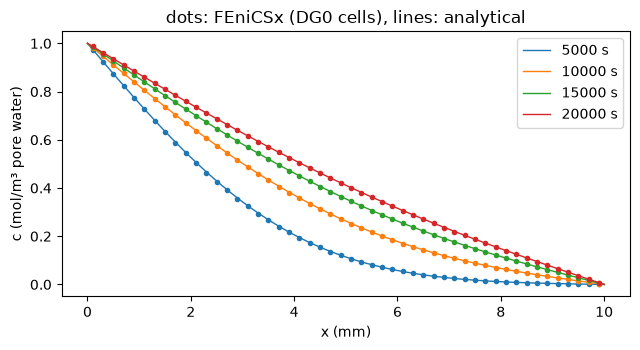

max |error| at t = 20000 s: 9.33e-04 mol/m3


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

p = pd.read_csv('t01_tracer/results/profiles.csv')
L, D = 0.01, 4.0e-10 / 0.4

def exact(x, t, terms=400):
    n = np.arange(1, terms + 1)[:, None]
    return 1 - x / L - 2 / np.pi * np.sum(np.sin(n * np.pi * x / L) / n * np.exp(-(n * np.pi) ** 2 * D * t / L ** 2), axis=0)

fig, ax = plt.subplots(figsize=(6.5, 3.6))
xf = np.linspace(0, L, 400)
for t, g in p[p.time_s > 0].groupby('time_s'):
    line, = ax.plot(g.x_m * 1e3, g.tracer_c_mol_m3_water, 'o', ms=3)
    ax.plot(xf * 1e3, exact(xf, t), '-', color=line.get_color(), lw=1, label=f'{t:.0f} s')
ax.set_xlabel('x (mm)'); ax.set_ylabel('c (mol/m³ pore water)')
ax.set_title('dots: FEniCSx (DG0 cells), lines: analytical')
ax.legend(); plt.tight_layout(); plt.show()

last = p[p.time_s == p.time_s.max()]
err = np.max(np.abs(last.tracer_c_mol_m3_water - exact(last.x_m.values, last.time_s.values[0])))
print(f'max |error| at t = {last.time_s.values[0]:.0f} s: {err:.2e} mol/m3')

**So liest man das.** Die größte Abweichung von der exakten Lösung beträgt etwa $10^{-3}$ mol/m³, also 0,1 % des Randwerts. Zwei
Näherungen tragen bei: das implizite Euler-Verfahren erster Ordnung in der Zeit und ein Wert pro Zelle im Ort. Um herauszufinden, welche
überwiegt, ändern Sie jeweils nur eine: `dt` halbieren bei festem Gitter, dann `cells` verdoppeln bei festem `dt`.

## Massenbilanz

Der Code prüft in jedem Schritt, dass sich die Menge in der Säule nur um das ändert, was über die Ränder ging. `mass_balance.csv` enthält das Inventar
(mol pro m² Querschnitt), den kumulierten Randeintrag und ihre Differenz. In einem gesunden Lauf bleibt die Differenz auf Rundungsniveau (hier etwa
$10^{-17}$ mol/m²), und die beiden Kurven liegen übereinander.

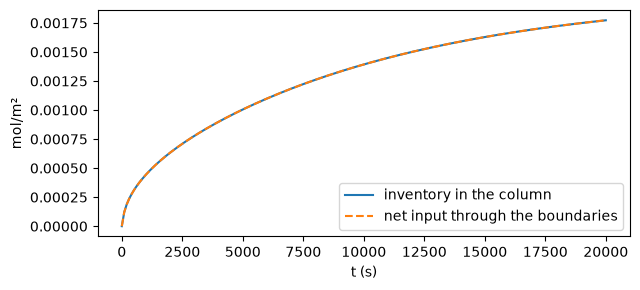

largest balance error: 4.380176776841438e-17 mol/m2


In [6]:
m = pd.read_csv('t01_tracer/results/mass_balance.csv')
fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(m.time_s, m.inventory_mol_m2, label='inventory in the column')
ax.plot(m.time_s, m.cumulative_net_in_mol_m2, '--', label='net input through the boundaries')
ax.set_xlabel('t (s)'); ax.set_ylabel('mol/m²'); ax.legend(); plt.tight_layout(); plt.show()
print('largest balance error:', abs(m.balance_error_mol_m2).max(), 'mol/m2')

## Eine Annahme ändern: geschlossenes rechtes Ende

Jetzt wird das rechte Ende verschlossen, statt es auf $c = 0$ zu halten. Physikalisch kann kein Tracer mehr die Säule verlassen; sie sollte sich also
langsam füllen, bis das ganze Porenwasser bei $c = 1$ liegt. In `case.yaml` ist das eine Änderung von zwei Zeilen:

```yaml
    right:
      type: no_flux
...
output:
  folder: results_noflux
```

Das Notebook nimmt die Änderung mit `yaml` vor und rechnet bis 100 000 s; dann hat das geschlossene Ende etwa 0,9 mol/m³ erreicht.
Gezeigt werden nur vier der 20 gespeicherten Profile.

In [7]:
import yaml
case = yaml.safe_load(open('t01_tracer/case.yaml'))
case['transport']['boundary']['right']['type'] = 'no_flux'
case['coupling']['time']['end'] = 100000
case['output']['folder'] = 'results_noflux'
yaml.safe_dump(case, open('t01_tracer/case_noflux.yaml', 'w'), sort_keys=False)
!{PY} ../FEniCSx_GEMS/coupling.py t01_tracer/case_noflux.yaml > /dev/null && tail -n 1 t01_tracer/results_noflux/simulation.log

Limit: saturated pore volume is assumed; aqueous volume mismatch is diagnostic only.


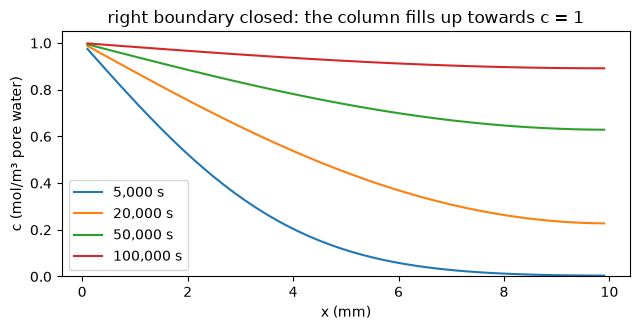

c at the closed end: 0.89 mol/m3 after 100 000 s


In [8]:
q = pd.read_csv('t01_tracer/results_noflux/profiles.csv')
fig, ax = plt.subplots(figsize=(6.5, 3.4))
for t in (5000, 20000, 50000, 100000):              # a few of the 20 saved times
    g = q[q.time_s == t]
    ax.plot(g.x_m * 1e3, g.tracer_c_mol_m3_water, label=f'{t:,} s')
ax.set_xlabel('x (mm)'); ax.set_ylabel('c (mol/m³ pore water)'); ax.set_ylim(0, 1.05)
ax.set_title('right boundary closed: the column fills up towards c = 1')
ax.legend(loc='lower left'); plt.tight_layout(); plt.show()
print(f"c at the closed end: {q[q.time_s == 100000].tracer_c_mol_m3_water.iloc[-1]:.2f} mol/m3 after 100 000 s")

## Was dieses Tutorial zeigt

- Der Transportlöser reproduziert die exakte Diffusionslösung mit diesem Gitter und Zeitschritt auf etwa 0,1 %, und die Massenbilanz schließt auf Rundungsniveau.
- Ein Randtyp ändert die Physik wie erwartet: Mit `no_flux` füllt sich die Säule, statt ein lineares Profil zu erreichen.
- Chemie, Strömung und Porositätsänderungen werden hier nicht geprüft; sie folgen in den nächsten Tutorials.

**Weiter:** [Tutorial 2](02_single_equilibrium.ipynb) schaltet GEMS ein und berechnet ein chemisches Gleichgewicht.